# HeartScope: Heart Disease Prediction System (Cardiac Risk Screener)

## How This Notebook Was Adapted from the Titanic Version
This notebook is adapted from the instructor-provided Titanic Passenger Survival Prediction System, following exactly the same steps (Label Encoding + Support Vector Classifier), but applied to the UCI Heart Disease (Cleveland) dataset.

- Only **4 input attributes** are used, as required by the assignment: `cp`, `exang`, `thal`, `ca`
- These 4 attributes were selected by comparing attribute combinations with 5-fold cross-validation
- The original target `num` (0 to 4) was converted to binary: 0 = No heart disease, 1-4 = Heart disease
- 6 rows with missing values in `ca` or `thal` were removed (303 rows -> 297 rows)

## Overview

##### **Definition** A binary classification ML task that predicts whether a patient has heart disease (Yes) or does not have heart disease (No) using four medical attributes (chest pain type, exercise-induced angina, thalassemia test result, and number of blocked major vessels).
##### **Application** It is mainly used for learning data science and for understanding how machine learning can support early screening for heart disease. It is a learning project and not a medical diagnosis tool.

##  Input and Output

###  Inputs (Features / Attributes)

| **Input Feature/Attribute**  |      **Possible Values**          |
| ---------------- | ---------------------------------------------------------- |
| **ChestPain**      | Typical Angina, Atypical Angina, Non-anginal Pain, Asymptomatic |
| **ExerciseAngina** | Yes, No                                                  |
| **Thal**           | Normal, Fixed Defect, Reversible Defect                  |
| **Vessels**        | 0 Vessels, 1 Vessel, 2 Vessels, 3 Vessels                |

### Output (Prediction)

| **Output Attribute** | **Possible Values** |
| -------------------- | ------------------- |
| **HeartDisease**     | Yes, No             |

### Examples (Heart Disease Dataset)

| ChestPain        | ExerciseAngina | Thal              | Vessels   | HeartDisease |
| :--------------- | :------------: | :---------------- | :-------- | :----------: |
| Typical Angina   | No             | Fixed Defect      | 0 Vessels | No           |
| Asymptomatic     | Yes            | Normal            | 3 Vessels | Yes          |
| Asymptomatic     | Yes            | Reversible Defect | 2 Vessels | Yes          |
| Non-anginal Pain | No             | Normal            | 0 Vessels | No           |
| Atypical Angina  | No             | Normal            | 0 Vessels | No           |

## Developer & System Information

| | |
| --- | --- |
| **Developer Name** | Maham-Ul-Akhtar Joyia |
| **Registration No.** | FA24-BCS-048 |
| **Course** | Machine Learning Fundamentals (AIC354) |
| **Instructor** | Dr. Jawad Shafi |
| **Program Name** | heart_disease_project |
| **IDE** | Google Colab (Jupyter Notebook) |
| **Programming Language** | Python 3 |
| **Dataset** | UCI Heart Disease (Cleveland), https://archive.ics.uci.edu/dataset/45/heart+disease |
| **Libraries** | NumPy, Pandas, Pickle (built-in), scikit-learn, PrettyTable, Matplotlib, Seaborn |
| **Date of Completion** | 17-Oct-2026 |

##  Contents
- Step 1: Load the Required Libraries
- Step 2: Read the Dataset
- Step 3: Explore and Pre-process the Dataset
  - Step 3.1: Explore the Dataset
  - Step 3.2: Pre-process the Dataset
- Step 4: Feature Selection
- Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)
  - Step 5.1: Fit the Label Encoders
  - Step 5.2: Encode the Target Column
  - Step 5.3: Encode the Input Columns
- Step 6: Training Phase
  - Step 6.1: Splitting Sample Data into Training Data and Testing Data
  - Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data
  - Step 6.3: Train the Support Vector Classifier
  - Step 6.4: Persist the Trained Model
- Step 7: Testing Phase
  - Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data
  - Step 7.2: Reload the Saved Model
  - Step 7.3: Evaluate the Machine Learning Model
    - Step 7.3.1: Make Predictions with the Trained Models on Testing Data
  - Step 7.4: Compute the Accuracy Score
  - **Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix) — NEW**
- Step 8: Application Phase
  - Step 8.1: Get Input from the User
  - Step 8.2: Convert User Input into Feature Vector
  - Step 8.3: Label Encoding of Feature Vector
  - Step 8.4: Reload the Saved Model
  - Step 8.5: Model Prediction
    - Step 8.5.1: Apply Model and Return Prediction to the User
- Step 9: Feedback Phase
  - Step 9.1: Collect Feedback from Users and Domain Experts
  - Step 9.2: List Possible Improvements
  - Step 9.3: Refine the Model Using Feedback
- **Step 10: Deploy Your Model as a Public Web App (NEW)**
  - Step 10.1: Why Deploy a Model?
  - Step 10.2: Create a GitHub Account and Repository
  - Step 10.3: Write a Simple Web App
  - Step 10.4: Create a Streamlit Community Cloud Account
  - Step 10.5: Deploy Your App
  - Step 10.6: Troubleshooting Common Issues
  - Step 10.7: Share Your Live Link


## Implementation – HeartScope Pipeline


###  Step 1: Load the Required Libraries

In [1]:
"""
Purpose of this cell:
---------------------
This cell imports the required libraries for building and evaluating a
machine learning model. It sets up tools for data manipulation, preprocessing,
splitting datasets, training a Support Vector Machine (SVM) model,
evaluating accuracy, and displaying results in tabular form.
"""

# Import numerical computing library (used for arrays, math operations, etc.)
import numpy as np

# Import data manipulation library (used for DataFrames, reading/writing data, etc.)
import pandas as pd

# Import pickle (used for saving and loading Python objects/models)
import pickle

# Import train_test_split (used to divide dataset into training and testing sets)
from sklearn.model_selection import train_test_split

# Import LabelEncoder (used to convert categorical values into numeric codes)
from sklearn.preprocessing import LabelEncoder

# Import Support Vector Machine (SVM) model from scikit-learn
from sklearn import svm

# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Import PrettyTable (used to display results in a clean, table format)
from prettytable import PrettyTable

# Import plotting libraries (used for the confusion matrix heatmap)
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Prepare the dataset (one-time): select 4 input attributes and convert to text categories
import pandas as pd

cols = ['age','sex','cp','trestbps','chol','fbs','restecg',
        'thalach','exang','oldpeak','slope','ca','thal','num']
df = pd.read_csv('processed.cleveland.data', header=None,
                 names=cols, na_values='?')

# Remove the 6 rows that have missing values in 'ca' or 'thal'
df = df.dropna(subset=['ca', 'thal'])

data = df[['cp', 'exang', 'thal', 'ca', 'num']].copy()

data['cp'] = data['cp'].map({1: 'Typical Angina', 2: 'Atypical Angina',
                             3: 'Non-anginal Pain', 4: 'Asymptomatic'})
data['exang'] = data['exang'].map({0: 'No', 1: 'Yes'})
data['thal'] = data['thal'].map({3: 'Normal', 6: 'Fixed Defect', 7: 'Reversible Defect'})
data['ca'] = data['ca'].astype(int).map({0: '0 Vessels', 1: '1 Vessel',
                                         2: '2 Vessels', 3: '3 Vessels'})

# Target: 0 = No heart disease, 1-4 = Heart disease
data['HeartDisease'] = data['num'].apply(lambda x: 'Yes' if x > 0 else 'No')
data = data.drop(columns=['num'])
data.columns = ['ChestPain', 'ExerciseAngina', 'Thal', 'Vessels', 'HeartDisease']

data.to_csv('heart-data.csv', index=False)
print("Saved: heart-data.csv", data.shape)

Saved: heart-data.csv (297, 5)


### Step 2: Read the Dataset

In [3]:
"""
Purpose of this cell:
---------------------
This cell loads the Heart Disease dataset from a CSV file into a
pandas DataFrame. It then displays the dataset so that the reader can
see the raw data being used for further processing and model training.
"""

# Read the CSV file and load it into a pandas DataFrame
# 'heart-data.csv' should be present in the working directory
records_df = pd.read_csv("heart-data.csv")

# Print a header to indicate that sample data is being displayed
print("\n\nSample Data:")
print("============\n")

# Configure pandas to display all rows and columns (so nothing gets hidden with '...')
pd.set_option("display.max_rows", None, "display.max_columns", None)

# Display the dataset
print(records_df)



Sample Data:

            ChestPain ExerciseAngina               Thal    Vessels  \
0      Typical Angina             No       Fixed Defect  0 Vessels   
1        Asymptomatic            Yes             Normal  3 Vessels   
2        Asymptomatic            Yes  Reversible Defect  2 Vessels   
3    Non-anginal Pain             No             Normal  0 Vessels   
4     Atypical Angina             No             Normal  0 Vessels   
5     Atypical Angina             No             Normal  0 Vessels   
6        Asymptomatic             No             Normal  2 Vessels   
7        Asymptomatic            Yes             Normal  0 Vessels   
8        Asymptomatic             No  Reversible Defect   1 Vessel   
9        Asymptomatic            Yes  Reversible Defect  0 Vessels   
10       Asymptomatic             No       Fixed Defect  0 Vessels   
11    Atypical Angina             No             Normal  0 Vessels   
12   Non-anginal Pain            Yes       Fixed Defect   1 Vessel   
13  

### Step 3: Explore and Pre-process the Dataset

####  Step 3.1: Explore the Dataset

In [4]:
"""
Purpose of this cell:
---------------------
This cell helps us understand the dataset by:
1. Printing the names of all attributes (columns) in the DataFrame.
2. Showing the total number of instances (rows) available in the dataset.
"""

# Print a header for clarity
print("\n\nAttributes in Sample Data:")
print("==========================\n")

# Display all column names (attributes) in the dataset
print(records_df.columns)

# Print a header for instance count
print("\n\nNumber of Instances in Sample Data:", records_df["ChestPain"].count())
print("========================================\n")



Attributes in Sample Data:

Index(['ChestPain', 'ExerciseAngina', 'Thal', 'Vessels', 'HeartDisease'], dtype='object')


Number of Instances in Sample Data: 297



#### Step 3.2: Pre-process the Dataset
o   Sample Data is already Preprocessed
o   No Preprocessing needs to be Performed

#### Step 4: Feature Selection
o   Features are already Extracted
o   No Feature Extraction needs to be Performed

### Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)

#### Step 5.1: Fit the Label Encoders

In [5]:
"""
Purpose of this cell:
---------------------
This cell sets up and trains Label Encoders.
Label Encoding is used to convert categorical values (like 'Yes', 'No',
'Normal', 'Fixed Defect') into numeric codes that machine learning
algorithms can work with.

Steps:
1. Define sample label categories for each attribute.
2. Initialize a LabelEncoder for each attribute.
3. Train (fit) each LabelEncoder with its respective category values.
"""

# Define label categories for each feature
# These are possible values each column can have in the dataset
chestpain = pd.DataFrame({"ChestPain": ["Typical Angina", "Atypical Angina",
                                        "Non-anginal Pain", "Asymptomatic"]})
exerciseangina = pd.DataFrame({"ExerciseAngina": ["Yes", "No"]})
thal = pd.DataFrame({"Thal": ["Normal", "Fixed Defect", "Reversible Defect"]})
vessels = pd.DataFrame({"Vessels": ["0 Vessels", "1 Vessel", "2 Vessels", "3 Vessels"]})
heartdisease = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

# Initialize LabelEncoders (one for each attribute)
chestpain_label_encoder = LabelEncoder()
exerciseangina_label_encoder = LabelEncoder()
thal_label_encoder = LabelEncoder()
vessels_label_encoder = LabelEncoder()
heartdisease_label_encoder = LabelEncoder()

# Train (fit) each LabelEncoder on its category values
chestpain_label_encoder.fit(np.ravel(chestpain))
exerciseangina_label_encoder.fit(np.ravel(exerciseangina))
thal_label_encoder.fit(np.ravel(thal))
vessels_label_encoder.fit(np.ravel(vessels))
heartdisease_label_encoder.fit(np.ravel(heartdisease))

# Show how each encoder maps text to numbers
print("ChestPain  :", dict(zip(chestpain_label_encoder.classes_, chestpain_label_encoder.transform(chestpain_label_encoder.classes_))))
print("ExerciseAngina:", dict(zip(exerciseangina_label_encoder.classes_, exerciseangina_label_encoder.transform(exerciseangina_label_encoder.classes_))))
print("Thal       :", dict(zip(thal_label_encoder.classes_, thal_label_encoder.transform(thal_label_encoder.classes_))))
print("Vessels    :", dict(zip(vessels_label_encoder.classes_, vessels_label_encoder.transform(vessels_label_encoder.classes_))))
print("HeartDisease:", dict(zip(heartdisease_label_encoder.classes_, heartdisease_label_encoder.transform(heartdisease_label_encoder.classes_))))

ChestPain  : {'Asymptomatic': np.int64(0), 'Atypical Angina': np.int64(1), 'Non-anginal Pain': np.int64(2), 'Typical Angina': np.int64(3)}
ExerciseAngina: {'No': np.int64(0), 'Yes': np.int64(1)}
Thal       : {'Fixed Defect': np.int64(0), 'Normal': np.int64(1), 'Reversible Defect': np.int64(2)}
Vessels    : {'0 Vessels': np.int64(0), '1 Vessel': np.int64(1), '2 Vessels': np.int64(2), '3 Vessels': np.int64(3)}
HeartDisease: {'No': np.int64(0), 'Yes': np.int64(1)}


#### Step 5.2: Encode the Target Column

In [6]:
"""
Purpose of this cell:
---------------------
This cell applies Label Encoding to the target/output variable
("HeartDisease") in the dataset. The categorical values ("Yes", "No") are
converted into numerical values (1 and 0) that can be used by
machine learning algorithms.
"""

# Create copies of the dataset (one for encoded output, one to keep original)
df_label_out = records_df.copy()
df_untouched_copy = records_df.copy()

# Transform "HeartDisease" (categorical -> numeric) using the trained LabelEncoder
print("\n\nHeartDisease Attribute After Label Encoding:")
print("============================================\n")
records_df["encoded_heartdisease"] = heartdisease_label_encoder.transform(records_df["HeartDisease"])

print(records_df[["HeartDisease", "encoded_heartdisease"]])

# Replace the original output column with its encoded version
df_label_out[["ChestPain", "ExerciseAngina", "Thal", "Vessels", "HeartDisease"]] = \
    records_df[["ChestPain", "ExerciseAngina", "Thal", "Vessels", "encoded_heartdisease"]]

# Save the dataset with encoded output
df_label_out.to_csv(r"sample-data-encoded-output.csv", index=False, header=True)
print("\nSaved: sample-data-encoded-output.csv")



HeartDisease Attribute After Label Encoding:

    HeartDisease  encoded_heartdisease
0             No                     0
1            Yes                     1
2            Yes                     1
3             No                     0
4             No                     0
5             No                     0
6            Yes                     1
7             No                     0
8            Yes                     1
9            Yes                     1
10            No                     0
11            No                     0
12           Yes                     1
13            No                     0
14            No                     0
15            No                     0
16           Yes                     1
17            No                     0
18            No                     0
19            No                     0
20            No                     0
21            No                     0
22           Yes                     1
23           Yes

#### Step 5.3: Encode the Input Columns

In [7]:
"""
Purpose of this cell:
---------------------
This cell applies Label Encoding to the input attributes
(ChestPain, ExerciseAngina, Thal, Vessels), converting each text value
into a numeric code using the trained LabelEncoders.
"""

# Create a copy to hold the fully encoded dataset
df_fully_encoded = df_label_out.copy()

# Encode each input attribute with its trained LabelEncoder
df_label_out["encoded_chestpain"] = chestpain_label_encoder.transform(df_label_out["ChestPain"])
df_label_out["encoded_exerciseangina"] = exerciseangina_label_encoder.transform(df_label_out["ExerciseAngina"])
df_label_out["encoded_thal"] = thal_label_encoder.transform(df_label_out["Thal"])
df_label_out["encoded_vessels"] = vessels_label_encoder.transform(df_label_out["Vessels"])

# Replace the original input columns with their encoded versions
df_fully_encoded[["ChestPain", "ExerciseAngina", "Thal", "Vessels", "HeartDisease"]] = \
    df_label_out[["encoded_chestpain", "encoded_exerciseangina", "encoded_thal", "encoded_vessels", "HeartDisease"]]

print("\n\nSample Data after Label Encoding:")
print("=================================\n")
print(df_fully_encoded)

# Save the fully encoded dataset
df_fully_encoded.to_csv(r"sample-data-encoded.csv", index=False, header=True)
print("\nSaved: sample-data-encoded.csv")



Sample Data after Label Encoding:

     ChestPain  ExerciseAngina  Thal  Vessels  HeartDisease
0            3               0     0        0             0
1            0               1     1        3             1
2            0               1     2        2             1
3            2               0     1        0             0
4            1               0     1        0             0
5            1               0     1        0             0
6            0               0     1        2             1
7            0               1     1        0             0
8            0               0     2        1             1
9            0               1     2        0             1
10           0               0     0        0             0
11           1               0     1        0             0
12           2               1     0        1             1
13           1               0     2        0             0
14           2               0     2        0             0
15 

### Step 6: Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [8]:
"""
Purpose of this cell:
---------------------
This cell splits the dataset into Training Data and Testing Data.
- Training Data is used to teach the machine learning model.
- Testing Data is used to check how well the model performs on unseen data.
"""

# Split dataset into training (80%) and testing (20%)
# random_state=0 ensures reproducibility (same split every time)
# shuffle=True randomly mixes the rows before splitting
train_split, test_split = train_test_split(
    df_fully_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=True
)

# Save the training and testing datasets to CSV files
train_split.to_csv(r'training-data-encoded.csv', index=False, header=True)
test_split.to_csv(r'testing-data-encoded.csv', index=False, header=True)

print("Training Data shape:", train_split.shape)
print("Testing Data shape:", test_split.shape)

Training Data shape: (237, 5)
Testing Data shape: (60, 5)


### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [9]:
"""
Purpose of this cell:
---------------------
This cell separates the features (input vectors) and
the labels (output values) from the training dataset.
"""

# Extract input vectors (features) from training data
X_train_part = train_split.iloc[:, :-1]

# Extract output labels (target variable) from training data
y_train_part = train_split.iloc[:, -1]

print("Input vectors (train) shape:", X_train_part.shape)
print("Output labels (train) shape:", y_train_part.shape)


Input vectors (train) shape: (237, 4)
Output labels (train) shape: (237,)


### 6.3: Train the Support Vector Classifier

In [10]:
"""
Purpose of this cell:
---------------------
This cell trains a Support Vector Classifier (SVC) on the training data.
The SVC is a type of machine learning model that finds the best boundary
to separate different classes (e.g., heart disease vs. no heart disease).
"""

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

# Initialize the Support Vector Classifier with chosen parameters
svc_clf = svm.SVC(gamma='auto', random_state=0)

# Train the model using the training data (features and labels)
svc_clf.fit(X_train_part, np.ravel(y_train_part))

# Print trained model details (parameters and values)
print(svc_clf)




Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


### Step 6.4: Persist the Trained Model

In [11]:
"""
Purpose of this cell:
---------------------
This cell saves the trained Support Vector Classifier (SVC)
model to your computer so it can be reused later without retraining.
"""

# Save the trained SVC model to a file named "heart_svc_trained_model.pkl"
pickle.dump(svc_clf, open('heart_svc_trained_model.pkl', 'wb'))
print("Saved: heart_svc_trained_model.pkl")

Saved: heart_svc_trained_model.pkl


### Step 7: Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [12]:
"""
Purpose of this cell:
---------------------
This cell separates the features (inputs) and the labels (outputs)
from the testing dataset.
"""

X_test_part = test_split.iloc[:, :-1]
y_test_part = test_split.iloc[:, -1]

print("Input vectors (test) shape:", X_test_part.shape)
print("Output labels (test) shape:", y_test_part.shape)


Input vectors (test) shape: (60, 4)
Output labels (test) shape: (60,)


### Step 7.2: Reload the Saved Model

In [13]:
"""
Purpose of this cell:
---------------------
This cell loads the previously saved Support Vector Classifier (SVC)
model from disk into memory.
"""

model = pickle.load(open('heart_svc_trained_model.pkl', 'rb'))
print("Model loaded from heart_svc_trained_model.pkl")

Model loaded from heart_svc_trained_model.pkl


### Step 7.3: Evaluate the Machine Learning Model

#### Step 7.3.1: Make Predictions with the Trained Models on Testing Data

In [14]:
"""
Purpose of this cell:
---------------------
This cell evaluates the trained Support Vector Classifier (SVC)
on the testing data.
"""

scored_test_set = model.predict(X_test_part)

pd.options.mode.chained_assignment = None
test_split["Predictions"] = scored_test_set
test_split.to_csv(r'model-predictions.csv', index=False, header=True)

scored_test_set = test_split
print("\n\nPredictions Returned by heart_svc_trained_model:")
print("================================================\n")
print(scored_test_set)



Predictions Returned by heart_svc_trained_model:

     ChestPain  ExerciseAngina  Thal  Vessels  HeartDisease  Predictions
111          3               0     0        0             0            0
150          0               0     1        0             0            0
12           2               1     0        1             1            0
216          0               0     1        0             0            0
139          1               1     1        0             0            0
74           0               0     1        1             1            1
208          3               1     2        0             1            0
171          0               0     1        0             0            0
187          2               0     2        3             1            0
214          0               1     1        0             0            1
73           0               0     0        2             1            1
15           2               0     1        0             0            0

### Step 7.4: Compute the Accuracy Score

In [15]:
"""
Purpose of this cell:
---------------------
This cell calculates how accurate the trained model is on the
testing dataset.
"""

holdout_accuracy = accuracy_score(
    scored_test_set["HeartDisease"],
    scored_test_set["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(holdout_accuracy, 2))



Accuracy Score:

0.75


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix) (NEW)


Classification Report:

                      precision    recall  f1-score   support

No Heart Disease (0)       0.70      0.87      0.78        30
   Heart Disease (1)       0.83      0.63      0.72        30

            accuracy                           0.75        60
           macro avg       0.76      0.75      0.75        60
        weighted avg       0.76      0.75      0.75        60


Confusion Matrix:

                    Predicted: No Disease  Predicted: Disease
Actual: No Disease                     26                   4
Actual: Disease                        11                  19


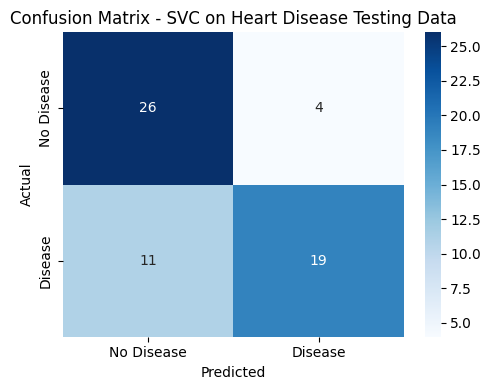

In [16]:
"""
Purpose of this cell:
---------------------
Accuracy alone can be misleading, especially on small or imbalanced
datasets. This section adds the standard classification metrics:
- Precision: of everyone the model predicted as "Heart Disease", how many actually had it?
- Recall: of everyone who actually had heart disease, how many did the model catch?
- F1-score: the harmonic mean of precision and recall.
- Confusion Matrix: a table of correct vs. incorrect predictions per class.
"""

print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    scored_test_set["HeartDisease"],
    scored_test_set["Predictions"],
    target_names=["No Heart Disease (0)", "Heart Disease (1)"]
))

cm_array = confusion_matrix(scored_test_set["HeartDisease"], scored_test_set["Predictions"])
cm_frame = pd.DataFrame(
    cm_array,
    index=["Actual: No Disease", "Actual: Disease"],
    columns=["Predicted: No Disease", "Predicted: Disease"]
)
print("\nConfusion Matrix:")
print("==================\n")
print(cm_frame)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_array, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Disease', 'Disease'],
            yticklabels=['No Disease', 'Disease'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - SVC on Heart Disease Testing Data')
plt.tight_layout()
plt.show()

### Step 8: Application Phase (Using the Model on a New Patient)

#### Step 8.1: Get Input from the User

In [17]:
"""
Purpose of this cell:
---------------------
This cell allows the user to enter their own data
(ChestPain, ExerciseAngina, Thal, Vessels). In an interactive session,
you can replace the four demo lines below with input() calls:
    cp_value = input("Enter Chest Pain type (Typical Angina, Atypical Angina, Non-anginal Pain, Asymptomatic): ").strip()
    exang_value = input("Enter Exercise Induced Angina (Yes, No): ").strip()
    thal_value = input("Enter Thal (Normal, Fixed Defect, Reversible Defect): ").strip()
    ca_value = input("Enter Vessels (0 Vessels, 1 Vessel, 2 Vessels, 3 Vessels): ").strip()
"""

# Demo patient (edit these values, or swap in input() calls as shown above)
cp_value = "Asymptomatic"
exang_value = "Yes"
thal_value = "Reversible Defect"
ca_value = "2 Vessels"

print(f"ChestPain: {cp_value}, ExerciseAngina: {exang_value}, Thal: {thal_value}, Vessels: {ca_value}")

ChestPain: Asymptomatic, ExerciseAngina: Yes, Thal: Reversible Defect, Vessels: 2 Vessels


### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [18]:
"""
Purpose of this cell:
---------------------
This cell takes the user's input (entered as text)
and converts it into a structured feature vector (DataFrame).
"""

query_features = pd.DataFrame({
    'ChestPain': [cp_value],
    'ExerciseAngina': [exang_value],
    'Thal': [thal_value],
    'Vessels': [ca_value]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(query_features)



User Input Feature Vector:

      ChestPain ExerciseAngina               Thal    Vessels
0  Asymptomatic            Yes  Reversible Defect  2 Vessels


### Step 8.3: Label Encoding of Feature Vector (Exactly Same as Label Encoded Feature Vectors of Sample Data)

In [19]:
"""
Purpose of this cell:
---------------------
This cell encodes the user's input into numeric values
using the previously trained LabelEncoders.
"""

encoded_query = query_features.copy()

encoded_query["ChestPain"] = chestpain_label_encoder.transform(query_features['ChestPain'])
encoded_query["ExerciseAngina"] = exerciseangina_label_encoder.transform(query_features['ExerciseAngina'])
encoded_query["Thal"] = thal_label_encoder.transform(query_features['Thal'])
encoded_query["Vessels"] = vessels_label_encoder.transform(query_features['Vessels'])

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(encoded_query)



User Input Encoded Feature Vector:

   ChestPain  ExerciseAngina  Thal  Vessels
0          0               1     2        2


### Step 8.4: Reload the Saved Model

In [20]:
"""
Purpose of this cell:
---------------------
This cell loads the previously saved Support Vector Classifier (SVC)
model from the .pkl file into memory for the Application Phase.
"""

model = pickle.load(open('heart_svc_trained_model.pkl', 'rb'))
print("Model loaded from heart_svc_trained_model.pkl")

Model loaded from heart_svc_trained_model.pkl


### Step 8.5: Model Prediction

#### Step 8.5.1: Apply Model on the Label Encoded Feature Vector of unseen instance and return Prediction to the User

In [21]:
"""
Purpose of this cell:
---------------------
This cell uses the trained Support Vector Classifier (SVC)
to predict whether the patient has heart disease or not.
"""

disease_flag = model.predict(encoded_query)

if disease_flag == 1:
    prediction = "HEART DISEASE DETECTED"
if disease_flag == 0:
    prediction = "NO HEART DISEASE"

result_table = PrettyTable()
result_table.add_column("       ** Prediction **       ", [prediction])

print(result_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|     HEART DISEASE DETECTED     |
+--------------------------------+


### Step 9: Feedback Phase (Learning from Reviewers)

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [22]:
"""
Purpose of this cell:
---------------------
Step 9.1 (sample): Feedback collected from domain experts and testers
reviewing this model.
"""

feedback_log = pd.DataFrame({
    "Reviewer": ["Domain Expert (Cardiology)", "Domain Expert (Cardiology)", "Student Tester"],
    "Case": [
        "Asymptomatic chest pain, exercise angina Yes, Reversible Defect, 2 Vessels -> predicted HEART DISEASE DETECTED",
        "Model uses only 4 attributes (no age, cholesterol, blood pressure)",
        "Test accuracy is 0.75 on only 60 test patients",
    ],
    "Feedback": [
        "Matches clinical knowledge: these are all high-risk indicators for heart disease.",
        "Age, blood pressure and cholesterol are standard risk factors and should be considered in a real system.",
        "A small test set makes a single accuracy number unstable. Cross-validation gives a more reliable estimate.",
    ],
})
print(feedback_log.to_string(index=False))

                  Reviewer                                                                                                           Case                                                                                                   Feedback
Domain Expert (Cardiology) Asymptomatic chest pain, exercise angina Yes, Reversible Defect, 2 Vessels -> predicted HEART DISEASE DETECTED                          Matches clinical knowledge: these are all high-risk indicators for heart disease.
Domain Expert (Cardiology)                                             Model uses only 4 attributes (no age, cholesterol, blood pressure)   Age, blood pressure and cholesterol are standard risk factors and should be considered in a real system.
            Student Tester                                                                 Test accuracy is 0.75 on only 60 test patients A small test set makes a single accuracy number unstable. Cross-validation gives a more reliable estimate.


#### Step 9.2: List Possible Improvements

In [23]:
"""
Purpose of this cell:
---------------------
Step 9.2: Potential next_steps identified from the feedback above.
"""

next_steps = [
    "Add numeric features such as Age, Cholesterol and Max Heart Rate, which are known risk factors",
    "Use a larger dataset (e.g. combine Cleveland with the other UCI heart disease files) for more reliable results",
    "Use cross-validation instead of a single train/test split to get a more stable accuracy estimate",
    "Compare additional models (e.g. Random Forest, Logistic Regression) beyond SVC",
]
for i, item in enumerate(next_steps, 1):
    print(f"{i}. {item}")

1. Add numeric features such as Age, Cholesterol and Max Heart Rate, which are known risk factors
2. Use a larger dataset (e.g. combine Cleveland with the other UCI heart disease files) for more reliable results
3. Use cross-validation instead of a single train/test split to get a more stable accuracy estimate
4. Compare additional models (e.g. Random Forest, Logistic Regression) beyond SVC


#### Step 9.3: Refine the Model Using Feedback

In [24]:
"""
Purpose of this cell:
---------------------
Step 9.3: In a real deployment, the next version of this notebook would
retrain on the next_steps listed above and re-run Steps 6-7 to confirm
the new model's accuracy improves before replacing the deployed model.
"""

print("Next version: retrain with Age, Cholesterol and Max Heart Rate added, then re-evaluate before replacing heart_svc_trained_model.pkl")

Next version: retrain with Age, Cholesterol and Max Heart Rate added, then re-evaluate before replacing heart_svc_trained_model.pkl


## Final Summary
This Heart Disease Prediction System uses four input attributes: chest pain type, exercise-induced angina, thalassemia test result, and number of major blocked vessels. These four attributes were chosen by comparing combinations of attributes using 5-fold cross-validation. The Support Vector Classifier achieved an accuracy of 0.75 on the held-out test set of 60 patients. Cross-validation on this attribute combination gave a higher average accuracy of about 0.85, so the single-split result should be read with the small test size in mind. The model is a learning exercise and is not a medical diagnosis tool.